# Linguistic Marker Analysis — ETHICS Benchmark × DeepSeek R1 Distill Qwen-32B
### v9_pilot | 8.020 Respons | 41 Persona | 4 ETHICS Subsets

**Tujuan:** Menganalisis bagaimana 41 kondisi persona (religion, regional, gender, neutral)
mempengaruhi gaya moral reasoning, epistemic stance, framing etika, verbosity, dan pola argumentasi.

**Dimensi Analisis (12):**
1. Certainty & Hedging Markers  2. Moral Framing (deonto/conseq/virtue/religious)
3. Epistemic Stance (committed/conditional/refusal)  4. Response Length & Structure
5. Persona Acknowledgment  6. Discourse Connectives
7. Polarity Shift  8. Empathy Language
9. None Rate Analysis  10. Explicit vs Implicit Comparison
11. Religious Language  12. Statistical Testing

**Dataset:** `result_ethics_v9_pilot_deepseek_deepseek-r1-distill-qwen-32b.csv`  
**Kolom teks:** `explanation` | **Kolom label:** `parsed_answer`  
**Catatan:** `is_correct` dan `parsed_answer` menggunakan output dari v9_pilot reparse pipeline.


In [2]:
# ── Imports ───────────────────────────────────────────────────────────────────
import re, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from pathlib import Path
from collections import Counter
from scipy.stats import kruskal, mannwhitneyu, chi2_contingency, spearmanr
from itertools import combinations

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", font_scale=0.9)
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:.4f}".format)

# ── Paths ─────────────────────────────────────────────────────────────────────
DATA_PATH  = Path(r"D:\TugasAkhir\result\ETHICS\deepseek_deepseek-r1-distill-qwen-32b\result_ethics_v9_pilot_deepseek_deepseek-r1-distill-qwen-32b.csv")
OUTPUT_DIR = Path(r"D:\TugasAkhir\src\analysis\outputs_ethics")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ── Colour palette ─────────────────────────────────────────────────────────────
PERSONA_COLORS = {
    "religion": "#E74C3C", "regional": "#3498DB",
    "gender":   "#27AE60", "neutral":  "#95A5A6",
}
RELIGION_COLORS  = {"atheist":"#E74C3C","christian":"#3498DB","islam":"#27AE60","jewish":"#9B59B6"}
TYPE_COLORS      = {"explicit":"#2C3E50","implicit":"#E67E22","neutral":"#95A5A6"}
FIGURE_DPI = 150
print("✅ Imports ready")


✅ Imports ready


## Section 1: Inspeksi Dataset

In [3]:
# ── Load & Parse ─────────────────────────────────────────────────────────────
df = pd.read_csv(DATA_PATH, low_memory=False)
df.columns = df.columns.str.strip()

TEXT_COL  = "explanation"
LABEL_COL = "parsed_answer"
df["text"] = df[TEXT_COL].fillna("").astype(str)
df["wc"]   = df["text"].apply(lambda t: max(len(re.findall(r"\b\w+\b", t)), 1))

# ── Persona decomposition ──────────────────────────────────────────────────────
def parse_persona(p):
    p = str(p)
    if p == "neutral": return "neutral","neutral","neutral"
    for rel in ["atheist","christian","islam","jewish"]:
        if p.startswith(rel):
            ptype = "explicit" if "explicit" in p else "implicit"
            return rel, "religion", ptype
    for reg in ["african","east_asian","south_asian","western"]:
        if p.startswith(reg):
            ptype = "explicit" if "explicit" in p else "implicit"
            return reg, "regional", ptype
    if p.startswith("man"):
        ptype = "explicit" if "explicit" in p else "implicit"
        return "man", "gender", ptype
    if p.startswith("woman"):
        ptype = "explicit" if "explicit" in p else "implicit"
        return "woman", "gender", ptype
    return "other","other","other"

df[["persona_base","persona_category","persona_type"]] = df["persona"].apply(
    lambda p: pd.Series(parse_persona(p)))
df["is_none"]  = df["parse_source"] == "none"
df["is_empty"] = df["text"].str.strip() == ""

print(f"Loaded: {len(df):,} rows | {df['persona'].nunique()} personas | {df['subset'].nunique()} subsets")
print(f"Parse coverage: {(~df['is_none']).mean()*100:.1f}% | Empty: {df['is_empty'].sum()}")
print(f"\nPersona distribution:\n{df['persona_category'].value_counts().to_string()}")
print(f"\nParse source:\n{df['parse_source'].value_counts().head(8).to_string()}")


Loaded: 41,114 rows | 49 personas | 4 subsets
Parse coverage: 65.9% | Empty: 749

Persona distribution:
persona_category
religion    24224
gender      12112
regional     3200
neutral      1514
other          64

Parse source:
parse_source
none               14032
original            7582
answer_flexible     4836
semantic_is         3962
bare                2961
answer_marker       2223
answer_no_colon     1652
paren_verdict        849


None Rate per Persona (%):
persona
atheist_implicit_1               57.7000
south_asian_implicit_1           56.0000
christian_implicit_1             51.5000
jewish_implicit_1                50.0000
north_american_implicit_1        50.0000
african_implicit_1               47.5000
jewish_implicit_3                47.0000
christian_implicit_2             44.5000
christian_implicit_3             44.3000
islam_implicit_3                 43.1000
east_asian_implicit_2            42.0000
atheist_implicit_3               38.8000
atheist_implicit_2               38.8000
islam_implicit_1                 38.4000
sub_saharan_african_implicit_1   37.5000
north_american_implicit_3        37.5000
sub_saharan_african_implicit_3   37.5000
islam_implicit_2                 36.7000
woman_implicit_1                 35.7000
man_implicit_1                   35.7000
jewish_implicit_2                34.8000
western_implicit_2               34.0000
woman_implicit_2                 33.6000
east_asian_implicit_3 

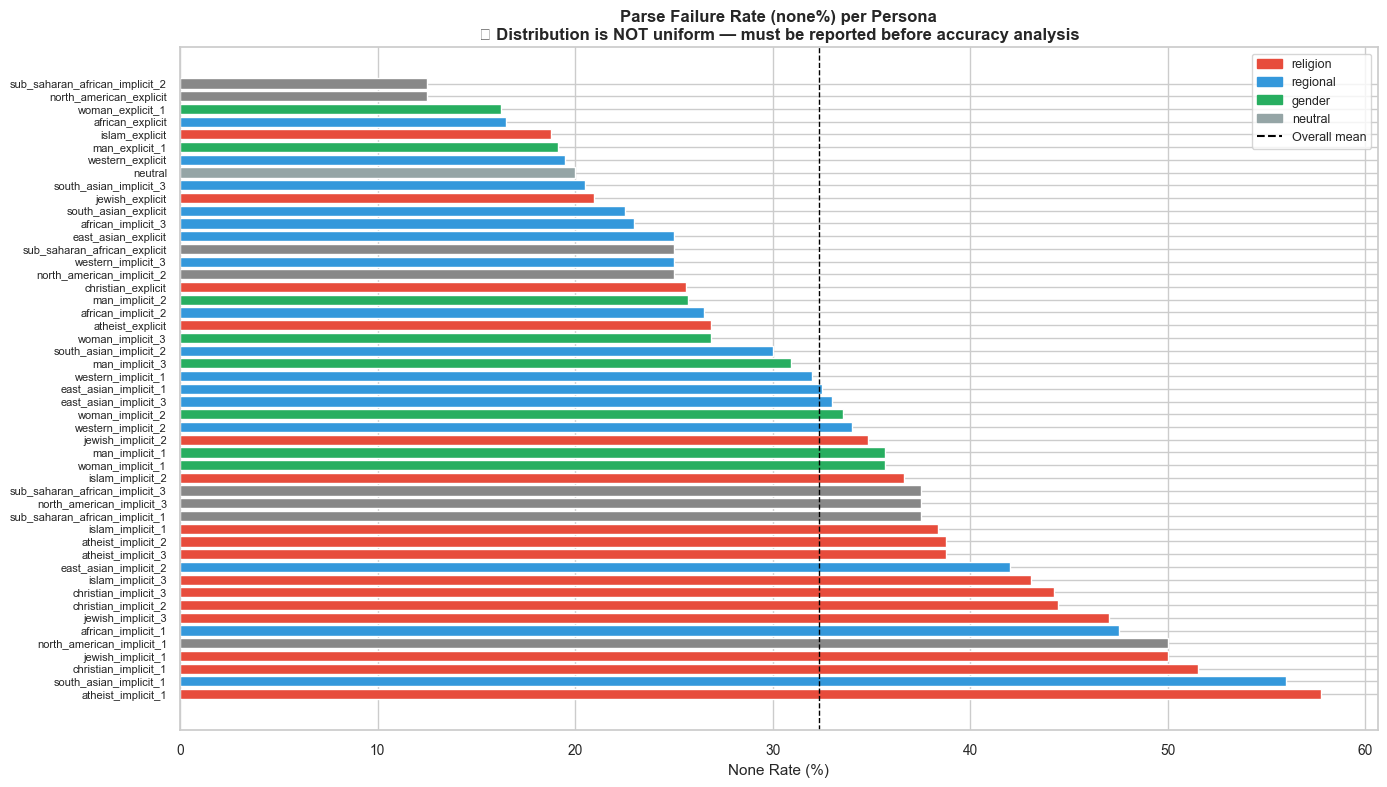

✅ Fig 1 saved


In [4]:
# ── None Rate per Persona (Kritis: harus dicek sebelum analisis akurasi) ─────
none_per_persona = df.groupby("persona")["is_none"].mean().mul(100).sort_values(ascending=False)
print("None Rate per Persona (%):")
print(none_per_persona.round(1).to_string())

fig, ax = plt.subplots(figsize=(14, 8))
colors = [PERSONA_COLORS.get(
    df[df["persona"]==p]["persona_category"].iloc[0], "#888") for p in none_per_persona.index]
bars = ax.barh(none_per_persona.index, none_per_persona.values, color=colors, edgecolor="white")
ax.axvline(none_per_persona.mean(), color="black", linestyle="--", linewidth=1,
           label=f"Overall mean: {none_per_persona.mean():.1f}%")
ax.set_xlabel("None Rate (%)", fontsize=11)
ax.set_title("Parse Failure Rate (none%) per Persona\n"
             "⚠ Distribution is NOT uniform — must be reported before accuracy analysis",
             fontsize=12, fontweight="bold")
ax.legend(fontsize=9); ax.tick_params(axis="y", labelsize=8)
patches = [mpatches.Patch(color=v, label=k) for k,v in PERSONA_COLORS.items()]
ax.legend(handles=patches+[plt.Line2D([0],[0],color='black',linestyle='--',label="Overall mean")],
          fontsize=9)
plt.tight_layout()
plt.savefig(OUTPUT_DIR/"fig1_none_rate_per_persona.png", dpi=FIGURE_DPI, bbox_inches="tight")
plt.show()
print("✅ Fig 1 saved")


## Section 2: Basic Linguistic Markers

In [5]:
# ── Basic Features ────────────────────────────────────────────────────────────
def ttr(t, n=300):
    words = re.findall(r"\b[a-z]+\b", t.lower())[:n]
    return len(set(words))/len(words) if words else 0.0

def count_sents(t):
    return max(len([s for s in re.split(r"(?<=[.!?])\s+", t) if s.strip()]), 1)

df["char_count"]   = df["text"].str.len()
df["sent_count"]   = df["text"].apply(count_sents)
df["avg_sent_len"] = df["wc"] / df["sent_count"]
df["ttr"]          = df["text"].apply(ttr)
df["avg_word_len"] = df["text"].apply(
    lambda t: np.mean([len(w) for w in re.findall(r"\b[a-z]+\b", t.lower())]) if re.findall(r"\b[a-z]+\b", t) else 0)

df["has_numbered"] = df["text"].apply(lambda x: int(bool(re.search(r"(?m)^\s*\d+[\.)]\s+\w", x))))
df["has_bullet"]   = df["text"].apply(lambda x: int(bool(re.search(r"(?m)^\s*[-*•]\s+\w", x))))
df["has_bold_hdr"] = df["text"].apply(lambda x: int(bool(re.search(r"\*{1,2}[A-Z][^*\n]{2,40}\*{1,2}", x))))
df["has_structure"]= (df["has_numbered"] | df["has_bullet"] | df["has_bold_hdr"])

BASIC_COLS = ["wc","avg_sent_len","ttr","has_structure"]
summary = df.groupby(["persona_category","persona_type"])[BASIC_COLS].mean()
print("Basic markers per persona_category × type:")
print(summary.round(3).to_string())
summary.to_csv(OUTPUT_DIR/"basic_markers_summary.csv")


Basic markers per persona_category × type:
                                    wc  avg_sent_len    ttr  has_structure
persona_category persona_type                                             
gender           explicit      90.3810       13.5680 0.6450         0.3370
                 implicit     108.6420       14.7070 0.5660         0.3660
neutral          neutral      102.0710       13.7940 0.6420         0.4340
other            other        129.2030       15.2240 0.6310         0.4530
regional         explicit     102.5560       13.7040 0.6370         0.3940
                 implicit     120.7980       15.4740 0.6100         0.4110
religion         explicit      87.8720       13.9290 0.6510         0.2950
                 implicit     150.9270       15.8540 0.5960         0.5250


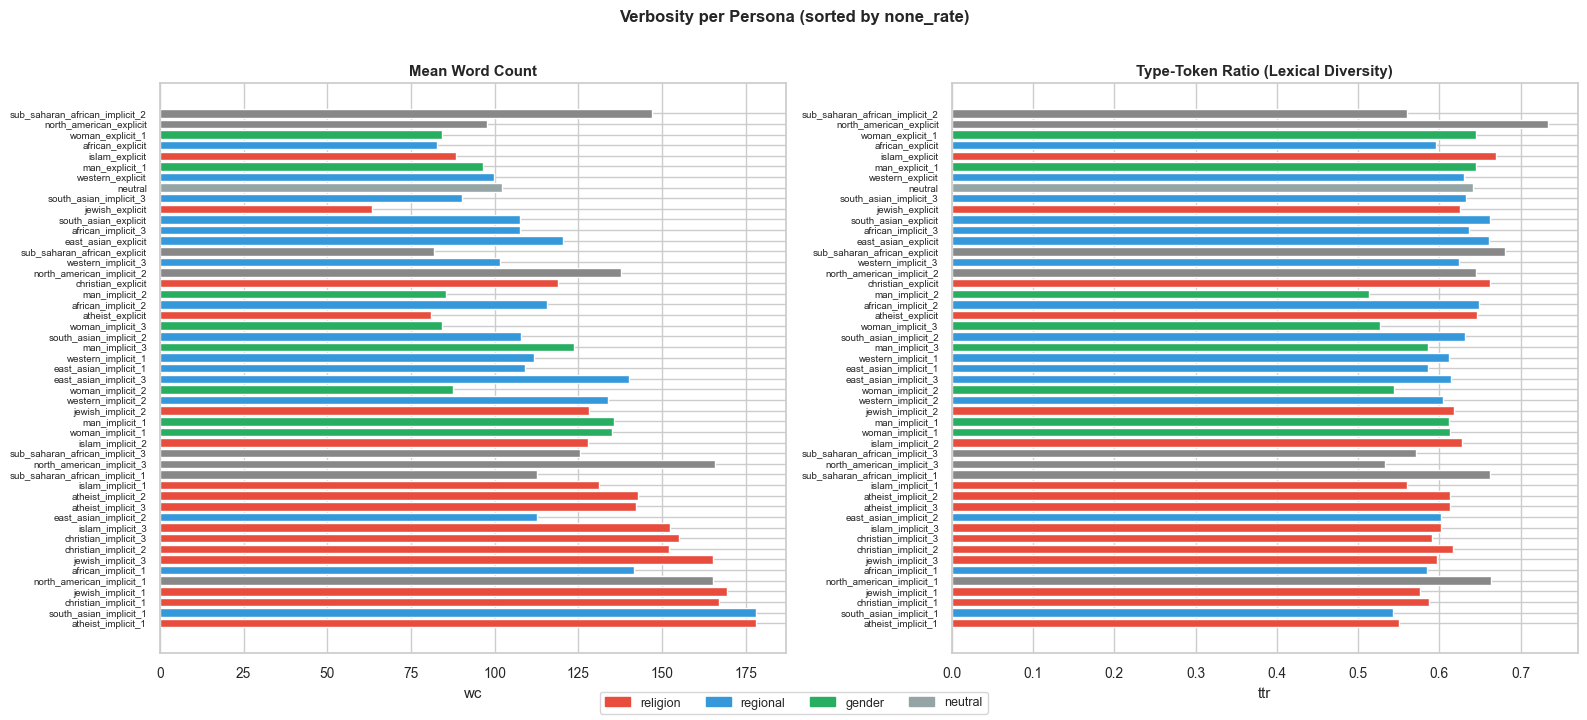

In [6]:
# ── Verbosity Heatmap ─────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax_i, (col, title) in enumerate([("wc","Mean Word Count"),("ttr","Type-Token Ratio (Lexical Diversity)")]):
    pivot = df.groupby(["persona","persona_category"])[col].mean().reset_index()
    order = df.groupby("persona")["is_none"].mean().sort_values(ascending=False).index.tolist()
    pivot_wide = pivot.set_index("persona")[[col]].reindex(order)
    cat_colors = [PERSONA_COLORS.get(df[df["persona"]==p]["persona_category"].iloc[0],"#888") for p in order]
    bars = axes[ax_i].barh(pivot_wide.index, pivot_wide[col].values, color=cat_colors, edgecolor="white")
    axes[ax_i].set_title(title, fontweight="bold")
    axes[ax_i].set_xlabel(col); axes[ax_i].tick_params(axis="y", labelsize=7)

patches = [mpatches.Patch(color=v, label=k) for k,v in PERSONA_COLORS.items()]
fig.legend(handles=patches, loc="lower center", ncol=4, fontsize=9)
plt.suptitle("Verbosity per Persona (sorted by none_rate)", fontsize=12, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(OUTPUT_DIR/"fig2_verbosity.png", dpi=FIGURE_DPI, bbox_inches="tight")
plt.show()


## Section 3: Certainty & Hedging Markers

In [7]:
# ── Certainty & Hedging ───────────────────────────────────────────────────────
# Hyland (2005) hedges/boosters adapted for moral reasoning domain

_CERTAINTY  = re.compile(r"\b(clearly|obviously|definitely|certainly|undeniably|absolutely|unquestionably|without\s+doubt|is\s+(?:clearly\s+)?(?:wrong|right|unacceptable|acceptable|unethical|ethical))\b", re.I)
_HEDGE_WEAK = re.compile(r"\b(might|may|could|perhaps|possibly|arguably|seemingly|appears?\s+to|tends?\s+to|relatively|somewhat)\b", re.I)
_HEDGE_STRONG = re.compile(r"\b(it\s+depends|without\s+more\s+context|cannot\s+determine|challenging\s+to\s+say|no\s+clear\s+(?:answer|verdict)|no\s+one.?size.?fits.?all|varies\s+by|context.?dependent|on\s+individual\s+circumstances|not\s+inherently\s+(?:right|wrong))\b", re.I)
_DISTANCING = re.compile(r"\b(one\s+could\s+argue|some\s+might\s+say|it\s+could\s+be\s+argued|from\s+(?:some\s+)?perspectives?|from\s+a\s+\w+\s+perspective|others?\s+might\s+(?:argue|view|see))\b", re.I)

df["certainty_d"]    = df["text"].apply(lambda x: len(_CERTAINTY.findall(x))) / df["wc"] * 100
df["hedge_weak_d"]   = df["text"].apply(lambda x: len(_HEDGE_WEAK.findall(x))) / df["wc"] * 100
df["hedge_strong_d"] = df["text"].apply(lambda x: len(_HEDGE_STRONG.findall(x))) / df["wc"] * 100
df["distancing_d"]   = df["text"].apply(lambda x: len(_DISTANCING.findall(x))) / df["wc"] * 100
df["hedge_total_d"]  = df["hedge_weak_d"] + df["hedge_strong_d"] + df["distancing_d"]
df["cert_hedge_ratio"] = df["certainty_d"] / (df["hedge_total_d"] + 0.001)

print("=== CERTAINTY & HEDGING per Persona Type ===")
print(df.groupby("persona_type")[["certainty_d","hedge_weak_d","hedge_strong_d","distancing_d","cert_hedge_ratio"]].mean().round(4).to_string())


=== CERTAINTY & HEDGING per Persona Type ===
              certainty_d  hedge_weak_d  hedge_strong_d  distancing_d  cert_hedge_ratio
persona_type                                                                           
explicit           0.3014        0.6942          0.0848        0.1197          213.2588
implicit           0.2436        0.9266          0.0985        0.0075          129.7686
neutral            0.3180        0.9444          0.0810        0.0048          222.3317
other              0.1817        0.8583          0.1315        0.0219          103.8696


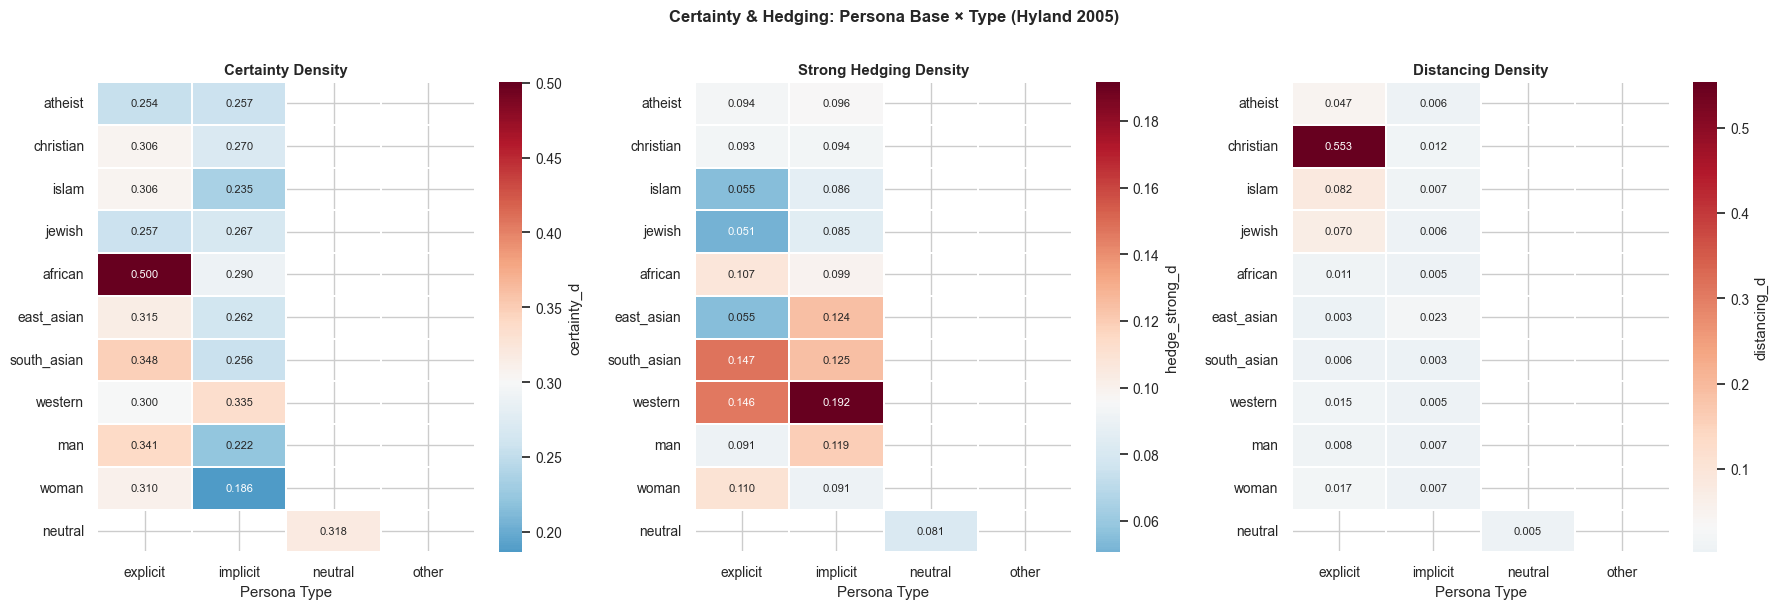

✅ Fig 3 saved


In [8]:
# ── Hedging Heatmap: Religion × Explicit/Implicit ─────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax_i, (col, title) in enumerate([
    ("certainty_d",   "Certainty Density"),
    ("hedge_strong_d","Strong Hedging Density"),
    ("distancing_d",  "Distancing Density"),
]):
    pivot = df.groupby(["persona_base","persona_type"])[col].mean().unstack("persona_type")
    pivot = pivot.reindex(["atheist","christian","islam","jewish","african","east_asian",
                           "south_asian","western","man","woman","neutral"])
    pivot = pivot.dropna(how="all")
    sns.heatmap(pivot, ax=axes[ax_i], cmap="RdBu_r", center=pivot.mean().mean(),
                annot=True, fmt=".3f", annot_kws={"size":8}, linewidths=0.3,
                cbar_kws={"label":col})
    axes[ax_i].set_title(title, fontweight="bold")
    axes[ax_i].set_xlabel("Persona Type"); axes[ax_i].set_ylabel("")

plt.suptitle("Certainty & Hedging: Persona Base × Type (Hyland 2005)",
             fontsize=12, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(OUTPUT_DIR/"fig3_certainty_hedging.png", dpi=FIGURE_DPI, bbox_inches="tight")
plt.show()
print("✅ Fig 3 saved")


## Section 4: Moral Framing

In [9]:
# ── Moral Framing ─────────────────────────────────────────────────────────────
# Kerangka: deontologis / konsekuensialis / virtue ethics / religius / kultural

_DEONTO   = re.compile(r"\b(duty|obligation|must|ought|principle|rule|moral\s+law|forbidden|permissible|violation|rights?|deontolog)\b", re.I)
_CONSEQ   = re.compile(r"\b(harm|benefit|outcome|consequence|impact|effect|result|utility|well.?being|welfare|greater\s+good|net\s+benefit)\b", re.I)
_VIRTUE   = re.compile(r"\b(character|integrity|virtue|honest|compassion|kindness|respect|decency|empathy|courage|wisdom|humility|generosity)\b", re.I)
_RELIG    = re.compile(r"\b(god|allah|lord|jesus|christ|bible|quran|torah|holy|prayer|faith|divine|blessed|sin|soul|heaven|scripture|verse|prophet|worship|haram|halal|shalom|commandment|sabbath|amen|inshallah|hallelujah|biblical|koranic|talmudic)\b", re.I)
_CULTURAL = re.compile(r"\b(cultural\s+norms?|tradition|context.?dependent|varies?\s+by\s+culture|societal|cultural\s+context|cultural\s+perspective|cultural\s+values?)\b", re.I)

df["deonto_d"]   = df["text"].apply(lambda x: len(_DEONTO.findall(x))) / df["wc"] * 100
df["conseq_d"]   = df["text"].apply(lambda x: len(_CONSEQ.findall(x))) / df["wc"] * 100
df["virtue_d"]   = df["text"].apply(lambda x: len(_VIRTUE.findall(x))) / df["wc"] * 100
df["religious_d"]= df["text"].apply(lambda x: len(_RELIG.findall(x))) / df["wc"] * 100
df["cultural_d"] = df["text"].apply(lambda x: len(_CULTURAL.findall(x))) / df["wc"] * 100
df["dc_ratio"]   = df["deonto_d"] / (df["conseq_d"] + 0.001)

print("=== MORAL FRAMING per Persona Category ===")
frame_cols = ["deonto_d","conseq_d","virtue_d","religious_d","cultural_d","dc_ratio"]
print(df.groupby("persona_category")[frame_cols].mean().round(4).to_string())


=== MORAL FRAMING per Persona Category ===
                  deonto_d  conseq_d  virtue_d  religious_d  cultural_d  dc_ratio
persona_category                                                                 
gender              0.6368    0.4027    0.2598       0.0062      0.1035  435.9937
neutral             0.6740    0.4945    0.2834       0.0069      0.1000  440.9035
other               0.5625    0.3971    0.3725       0.0000      0.0905  378.5576
regional            0.7111    0.4796    0.3470       0.0028      0.2788  464.6462
religion            0.6984    0.4346    0.5066       0.1732      0.1185  460.8091


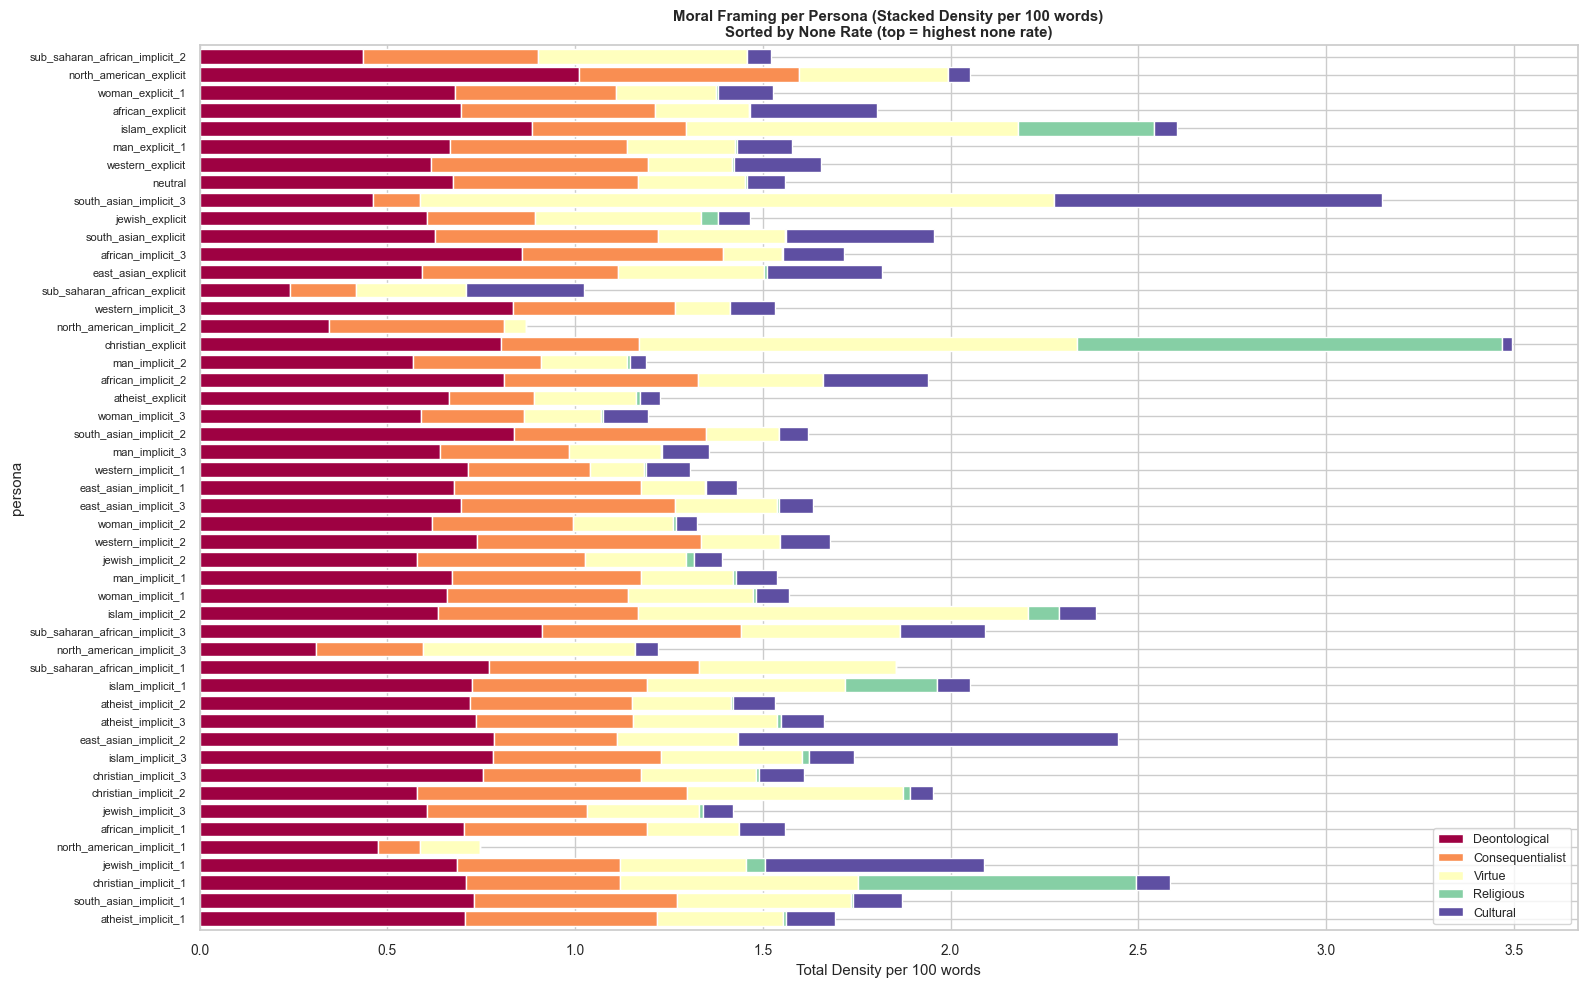

✅ Fig 4 saved


In [10]:
# ── Moral Framing Stacked Bar ─────────────────────────────────────────────────
framing_data = df.groupby("persona")[["deonto_d","conseq_d","virtue_d","religious_d","cultural_d"]].mean()
framing_data.columns = ["Deontological","Consequentialist","Virtue","Religious","Cultural"]
order = df.groupby("persona")["is_none"].mean().sort_values(ascending=False).index.tolist()
framing_data = framing_data.reindex(order)

fig, ax = plt.subplots(figsize=(16, 10))
framing_data.plot(kind="barh", stacked=True, ax=ax,
                  colormap="Spectral", edgecolor="white", width=0.8)
ax.set_title("Moral Framing per Persona (Stacked Density per 100 words)\n"
             "Sorted by None Rate (top = highest none rate)", fontweight="bold")
ax.set_xlabel("Total Density per 100 words")
ax.legend(loc="lower right", fontsize=9)
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.savefig(OUTPUT_DIR/"fig4_moral_framing.png", dpi=FIGURE_DPI, bbox_inches="tight")
plt.show()
print("✅ Fig 4 saved")


## Section 5: Epistemic Stance

In [11]:
# ── Epistemic Stance ──────────────────────────────────────────────────────────
_COMMITTED   = re.compile(r"\b(this\s+(?:action|behavior|scenario)\s+is\s+(?:clearly|obviously|definitely|wrong|right|unacceptable|acceptable)|therefore[,\s]+this\s+is|I\s+conclude\s+that|the\s+answer\s+is\s+(?:clearly|definitely)|this\s+is\s+(?:wrong|right|unethical|ethical|acceptable|unacceptable))\b", re.I)
_CONDITIONAL = re.compile(r"\b(it\s+depends|if\s+\w+[^.]{2,40}then|in\s+some\s+contexts?|under\s+some\s+circumstances?|neither\s+right\s+nor\s+wrong|not\s+inherently|depends\s+on\s+(?:the\s+)?(?:context|individual|circumstances|situation))\b", re.I)
_REFUSAL     = re.compile(r"\b(I\s+(?:cannot|can\'?t)\s+(?:determine|provide|give|make|offer)\b|need\s+more\s+(?:context|information|clarity)|could\s+you\s+(?:clarify|provide)\b|without\s+(?:more\s+)?(?:context|information)\b|as\s+an\s+AI[,\s]+I\s+don\'?t\s+(?:hold|have|possess))\b", re.I)

df["committed_s"]   = df["text"].apply(lambda x: len(_COMMITTED.findall(x)))
df["conditional_s"] = df["text"].apply(lambda x: len(_CONDITIONAL.findall(x)))
df["refusal_s"]     = df["text"].apply(lambda x: len(_REFUSAL.findall(x)))

def classify_stance(row):
    if row["refusal_s"] > 0: return "refusal"
    if row["conditional_s"] > row["committed_s"]: return "conditional"
    return "committed"

df["stance_type"] = df.apply(classify_stance, axis=1)

print("=== STANCE DISTRIBUTION per Persona ===")
stance_pct = df.groupby(["persona","stance_type"]).size().unstack(fill_value=0)
for col in ["committed","conditional","refusal"]:
    if col in stance_pct.columns:
        stance_pct[f"{col}%"] = (stance_pct[col] / stance_pct.sum(axis=1) * 100).round(1)
pct_cols = [c for c in stance_pct.columns if "%" in c]
print(stance_pct[pct_cols].sort_values("conditional%", ascending=False).to_string())
stance_pct.to_csv(OUTPUT_DIR/"stance_distribution.csv")


=== STANCE DISTRIBUTION per Persona ===
stance_type                     committed%  conditional%  refusal%
persona                                                           
woman_implicit_2                   78.2000       17.1000    3.5000
atheist_implicit_2                 79.7000       16.8000    2.4000
south_asian_implicit_2             74.0000       16.1000    2.8000
jewish_implicit_3                  80.8000       15.6000    2.6000
man_implicit_3                     79.7000       15.4000    3.9000
christian_implicit_1               82.4000       15.3000    1.4000
christian_implicit_2               82.1000       15.1000    1.9000
jewish_implicit_1                  82.2000       15.0000    1.8000
christian_implicit_3               82.7000       14.7000    1.7000
islam_implicit_1                   80.0000       14.6000    4.4000
woman_implicit_1                   82.9000       14.5000    1.7000
east_asian_implicit_2              69.5000       14.5000    7.7000
western_implicit_2    


⚠ Duplicate entries detected for committed:
           persona_base persona_type  count
1               african     implicit      3
3               atheist     implicit      3
5             christian     implicit      3
7            east_asian     implicit      3
9                 islam     implicit      3
11               jewish     implicit      3
13                  man     implicit      3
16       north_american     implicit      3
18          south_asian     implicit      3
20  sub_saharan_african     implicit      3

⚠ Duplicate entries detected for conditional:
           persona_base persona_type  count
1               african     implicit      3
3               atheist     implicit      3
5             christian     implicit      3
7            east_asian     implicit      3
9                 islam     implicit      3
11               jewish     implicit      3
13                  man     implicit      3
16       north_american     implicit      3
18          south_asian     

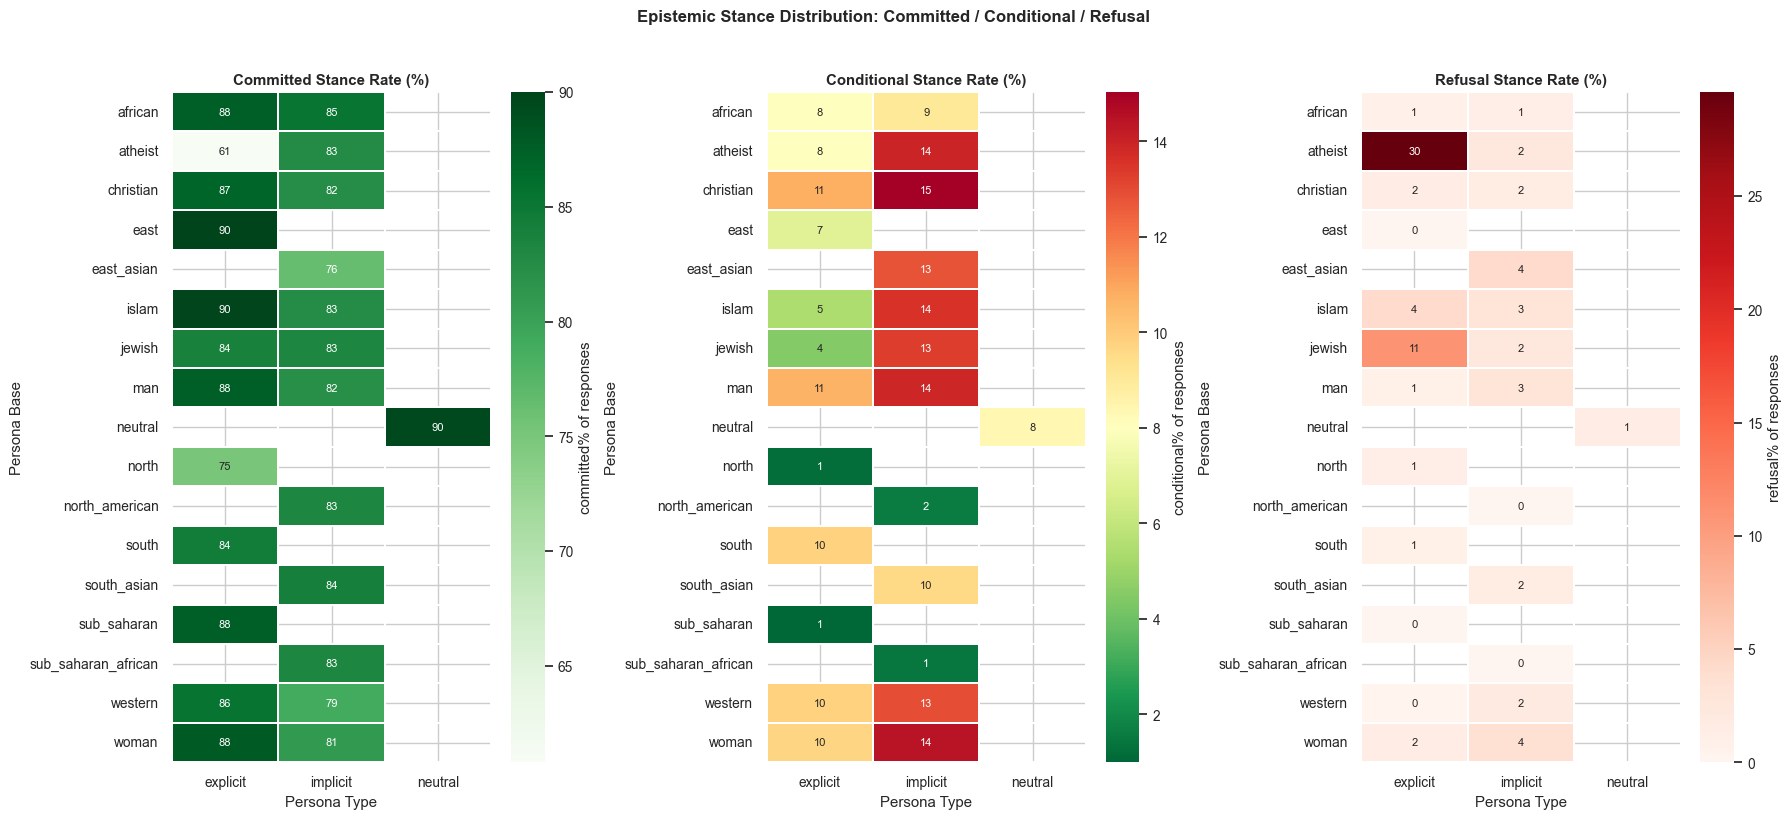

✅ Fig 5 saved


In [14]:
# ── Stance Heatmap ────────────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 3, figsize=(18, 8))

for ax_i, st in enumerate(["committed", "conditional", "refusal"]):

    col = f"{st}%"

    if col not in stance_pct.columns:
        axes[ax_i].set_visible(False)
        continue

    # Prepare dataframe
    pivot = stance_pct[[col]].reset_index().copy()

    pivot["persona_base"] = (
        pivot["persona"]
        .astype(str)
        .apply(lambda p: p.rsplit("_", 2)[0] if "_" in p else p)
    )

    pivot["persona_type"] = pivot["persona"].astype(str).apply(
        lambda p: (
            "explicit"
            if "explicit" in p.lower()
            else (
                "implicit"
                if "implicit" in p.lower()
                else "neutral"
            )
        )
    )

    # Check duplicate combinations
    dupes = (
        pivot.groupby(["persona_base", "persona_type"])
        .size()
        .reset_index(name="count")
        .query("count > 1")
    )

    if not dupes.empty:
        print(f"\n⚠ Duplicate entries detected for {st}:")
        print(dupes.head(10))

    # Safe reshape
    wide = pivot.pivot_table(
        index="persona_base",
        columns="persona_type",
        values=col,
        aggfunc="mean"  # use mean if duplicates exist
    )

    # Sort rows alphabetically
    wide = wide.sort_index()

    cmap = (
        "RdYlGn_r"
        if st == "conditional"
        else ("Reds" if st == "refusal" else "Greens")
    )

    sns.heatmap(
        wide,
        ax=axes[ax_i],
        cmap=cmap,
        annot=True,
        fmt=".0f",
        annot_kws={"size": 8},
        linewidths=0.3,
        cbar_kws={"label": f"{st}% of responses"},
    )

    axes[ax_i].set_title(
        f"{st.title()} Stance Rate (%)",
        fontweight="bold"
    )

    axes[ax_i].set_xlabel("Persona Type")
    axes[ax_i].set_ylabel("Persona Base")

plt.suptitle(
    "Epistemic Stance Distribution: Committed / Conditional / Refusal",
    fontsize=12,
    fontweight="bold",
    y=1.02,
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "fig5_epistemic_stance.png",
    dpi=FIGURE_DPI,
    bbox_inches="tight",
)

plt.show()

print("✅ Fig 5 saved")

## Section 6: Persona Acknowledgment & Religious Language

In [ ]:
# ── Persona Acknowledgment Analysis + Visualization ───────────────────────────

import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------------------
# Acknowledgment Patterns
# ------------------------------------------------------------------

_ACK_REL = re.compile(
    r"\b(as\s+a\s+(?:muslim|christian|jew|jewish|atheist)"
    r"|from\s+a\s+(?:christian|islamic|jewish|atheist)\s+perspective"
    r"|according\s+to\s+(?:islamic|christian|jewish|biblical)\s+(?:principles?|teachings?|values?)"
    r"|the\s+(?:bible|quran|torah)\s+(?:says?|teaches?|states?|commands?)"
    r"|haram|halal|biblically|scripturally"
    r"|from\s+a\s+religious\s+perspective)\b",
    re.I
)

_ACK_GEN = re.compile(
    r"\b(as\s+a\s+(?:woman|man)"
    r"|from\s+a\s+(?:woman'?s?|man'?s?)\s+perspective"
    r"|gender\s+roles?"
    r"|societal\s+expectations\s+for\s+(?:women|men))\b",
    re.I
)

_ACK_REG = re.compile(
    r"\b(in\s+(?:african|east\s+asian|south\s+asian|western)\s+(?:culture|tradition|society|context)"
    r"|african\s+tradition"
    r"|eastern\s+culture"
    r"|western\s+values?"
    r"|south\s+asian\s+norms?)\b",
    re.I
)

# ------------------------------------------------------------------
# Create Features
# ------------------------------------------------------------------

df["ack_religious"] = df["text"].apply(
    lambda x: int(bool(_ACK_REL.search(str(x))))
)

df["ack_gender"] = df["text"].apply(
    lambda x: int(bool(_ACK_GEN.search(str(x))))
)

df["ack_regional"] = df["text"].apply(
    lambda x: int(bool(_ACK_REG.search(str(x))))
)

df["has_any_ack"] = (
    df["ack_religious"]
    | df["ack_gender"]
    | df["ack_regional"]
)

# ------------------------------------------------------------------
# Tables
# ------------------------------------------------------------------

print("=== ACKNOWLEDGMENT RATE ===")

ack_cols = [
    "ack_religious",
    "ack_gender",
    "ack_regional",
    "has_any_ack"
]

print(
    df.groupby(
        ["persona_category", "persona_type"]
    )[ack_cols]
    .mean()
    .mul(100)
    .round(2)
    .to_string()
)

print("\n=== RELIGIOUS ACK: Explicit vs Implicit ===")

print(
    df.groupby(
        ["persona_base", "persona_type"]
    )["ack_religious"]
    .mean()
    .mul(100)
    .round(1)
    .unstack()
)

# ------------------------------------------------------------------
# Figure 1 - Overall Acknowledgment
# ------------------------------------------------------------------

overall = (
    df[ack_cols]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=overall.index,
    y=overall.values
)

for i, v in enumerate(overall.values):
    ax.text(
        i,
        v + 1,
        f"{v:.1f}%",
        ha="center",
        fontsize=9
    )

plt.title(
    "Overall Persona Acknowledgment Rate",
    fontweight="bold"
)

plt.ylabel("Percentage of Responses")
plt.xlabel("")
plt.xticks(rotation=20)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "fig_ack_overall.png",
    dpi=FIGURE_DPI,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------------
# Figure 2 - Religious Acknowledgment
# ------------------------------------------------------------------

religious_plot = (
    df.groupby(
        ["persona_category", "persona_type"]
    )["ack_religious"]
    .mean()
    .mul(100)
    .reset_index()
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=religious_plot,
    x="persona_category",
    y="ack_religious",
    hue="persona_type"
)

plt.title(
    "Religious Identity Acknowledgment",
    fontweight="bold"
)

plt.ylabel("% Responses")
plt.xlabel("Persona Category")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "fig_ack_religious.png",
    dpi=FIGURE_DPI,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------------
# Figure 3 - Gender Acknowledgment
# ------------------------------------------------------------------

gender_plot = (
    df.groupby(
        ["persona_category", "persona_type"]
    )["ack_gender"]
    .mean()
    .mul(100)
    .reset_index()
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=gender_plot,
    x="persona_category",
    y="ack_gender",
    hue="persona_type"
)

plt.title(
    "Gender Identity Acknowledgment",
    fontweight="bold"
)

plt.ylabel("% Responses")
plt.xlabel("Persona Category")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "fig_ack_gender.png",
    dpi=FIGURE_DPI,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------------
# Figure 4 - Regional Acknowledgment
# ------------------------------------------------------------------

regional_plot = (
    df.groupby(
        ["persona_category", "persona_type"]
    )["ack_regional"]
    .mean()
    .mul(100)
    .reset_index()
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=regional_plot,
    x="persona_category",
    y="ack_regional",
    hue="persona_type"
)

plt.title(
    "Regional Identity Acknowledgment",
    fontweight="bold"
)

plt.ylabel("% Responses")
plt.xlabel("Persona Category")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "fig_ack_regional.png",
    dpi=FIGURE_DPI,
    bbox_inches="tight"
)

plt.show()

print("\n✅ Acknowledgment analysis completed")
print("✅ fig_ack_overall.png")
print("✅ fig_ack_religious.png")
print("✅ fig_ack_gender.png")
print("✅ fig_ack_regional.png")

=== ACKNOWLEDGMENT RATE ===
                               ack_religious  ack_gender  ack_regional  has_any_ack
persona_category persona_type                                                      
gender           explicit             0.0000      1.2200        0.0000       1.2200
                 implicit             0.0000      0.2000        0.0000       0.2000
neutral          neutral              0.0000      0.0700        0.0000       0.0700
other            other                0.0000      0.0000        0.0000       0.0000
regional         explicit             0.0000      0.5000        1.2500       1.7500
                 implicit             0.0000      0.1200        0.0000       0.1200
religion         explicit            16.9300      0.0700        0.0200      16.9900
                 implicit             0.2800      0.1600        0.0000       0.4300

=== RELIGIOUS ACK: Explicit vs Implicit ===
persona_type  explicit  implicit  neutral  other
persona_base                          

## Section 7: Discourse Connectives & Polarity Shift

In [15]:
# ── Discourse Connectives ─────────────────────────────────────────────────────
_ADDITIVE    = re.compile(r"\b(furthermore|moreover|additionally|also\s+(?:important|note))\b", re.I)
_CONTRASTIVE = re.compile(r"\b(however|but|on\s+the\s+other\s+hand|nevertheless|yet\s+(?:this|it|the)|although|despite)\b", re.I)
_CAUSAL      = re.compile(r"\b(therefore|thus|hence|consequently|as\s+a\s+result|because|since\s+(?:this|it|the))\b", re.I)
_CONCESSIVE  = re.compile(r"\b(while|although|even\s+though|granted\s+that|admittedly|it\s+is\s+true\s+that)\b", re.I)
_CONDITIONAL = re.compile(r"\b(if|unless|provided\s+that|assuming\s+(?:that)?|in\s+the\s+event\s+that)\b", re.I)

df["additive_d"]      = df["text"].apply(lambda x: len(_ADDITIVE.findall(x))) / df["wc"] * 100
df["contrastive_d"]   = df["text"].apply(lambda x: len(_CONTRASTIVE.findall(x))) / df["wc"] * 100
df["causal_d"]        = df["text"].apply(lambda x: len(_CAUSAL.findall(x))) / df["wc"] * 100
df["concessive_d"]    = df["text"].apply(lambda x: len(_CONCESSIVE.findall(x))) / df["wc"] * 100
df["cond_conn_d"]     = df["text"].apply(lambda x: len(_CONDITIONAL.findall(x))) / df["wc"] * 100

# Polarity shift detection
_POS = re.compile(r"\b(right|acceptable|appropriate|ethical|good|correct|justified)\b", re.I)
_NEG = re.compile(r"\b(wrong|unacceptable|inappropriate|unethical|bad|incorrect|unjustified)\b", re.I)
def polarity_shift(text):
    if not text.strip(): return 0
    mid = len(text)//2; f,s = text[:mid],text[mid:]
    fp=bool(_POS.search(f))and not bool(_NEG.search(f))
    fn=bool(_NEG.search(f))and not bool(_POS.search(f))
    sp=bool(_POS.search(s))and not bool(_NEG.search(s))
    sn=bool(_NEG.search(s))and not bool(_POS.search(s))
    return int((fp and sn)or(fn and sp))
df["polarity_shift"] = df["text"].apply(polarity_shift)

# Empathy markers
_EMPATHY = re.compile(r"\b(it\s+is\s+understandable\s+that|this\s+is\s+a\s+valid\s+(?:concern|choice)|your\s+feelings?\s+are\s+valid|I\s+can\s+see\s+why|this\s+is\s+a\s+difficult\s+(?:situation|decision|choice))\b", re.I)
df["empathy_d"] = df["text"].apply(lambda x: len(_EMPATHY.findall(x))) / df["wc"] * 100

print("=== CONNECTIVES per Persona Category ===")
conn_cols = ["additive_d","contrastive_d","causal_d","concessive_d","cond_conn_d","polarity_shift"]
print(df.groupby("persona_category")[conn_cols].mean().round(4).to_string())


=== CONNECTIVES per Persona Category ===
                  additive_d  contrastive_d  causal_d  concessive_d  cond_conn_d  polarity_shift
persona_category                                                                                
gender                0.0251         0.4453    0.6692        0.3028       0.6492          0.0282
neutral               0.0153         0.3997    0.9010        0.4166       0.6349          0.0403
other                 0.0432         0.4131    0.7431        0.4182       0.4757          0.0156
regional              0.0346         0.4301    0.8370        0.3182       0.7135          0.0344
religion              0.0337         0.4665    0.6463        0.3239       0.6601          0.0257


## Section 8: Statistical Testing

In [16]:
# ── Statistical Testing ───────────────────────────────────────────────────────
from scipy.stats import kruskal, mannwhitneyu, chi2_contingency

def rank_biserial(u, n1, n2):
    return 1 - 2*u/(n1*n2)

# Test 1: Kruskal-Wallis per marker antar 41 persona
TEST_MARKERS = ["wc","certainty_d","hedge_weak_d","hedge_strong_d","distancing_d",
                "deonto_d","conseq_d","virtue_d","religious_d","cultural_d",
                "contrastive_d","causal_d","cond_conn_d","polarity_shift"]
TEST_MARKERS = [m for m in TEST_MARKERS if m in df.columns]

print("=== KRUSKAL-WALLIS: across 41 personas ===")
kw_results = []
for col in TEST_MARKERS:
    groups = [g[col].dropna().values for _,g in df.groupby("persona") if len(g)>=5]
    stat, p = kruskal(*groups)
    kw_results.append({"marker":col,"KW_stat":round(stat,2),"p_value":round(p,6),
                        "significant":"✓" if p<0.05 else "✗"})
kw_df = pd.DataFrame(kw_results)
print(kw_df.sort_values("p_value").to_string(index=False))

print("\n=== MANN-WHITNEY: Explicit vs Implicit ===")
ei_results = []
for col in TEST_MARKERS:
    e = df[df["persona_type"]=="explicit"][col].dropna()
    i_ = df[df["persona_type"]=="implicit"][col].dropna()
    if len(e)>=5 and len(i_)>=5:
        u,p = mannwhitneyu(e,i_,alternative="two-sided")
        r = rank_biserial(u,len(e),len(i_))
        direction = "Impl>Expl" if i_.mean()>e.mean() else "Expl>Impl"
        interp = "Large" if abs(r)>=0.5 else ("Medium" if abs(r)>=0.3 else ("Small" if abs(r)>=0.1 else "Negligible"))
        ei_results.append({"marker":col,"p_value":round(p,6),"effect_r":round(r,4),
                            "interpretation":interp,"direction":direction,
                            "sig":"✓" if p<0.05 else "✗"})
ei_df = pd.DataFrame(ei_results)
print(ei_df.sort_values("effect_r",key=abs,ascending=False).to_string(index=False))
ei_df.to_csv(OUTPUT_DIR/"statistical_tests_explicit_vs_implicit.csv",index=False)

print("\n=== SPEARMAN: hedge_strong_d vs none_rate per persona ===")
none_per = df.groupby("persona")["is_none"].mean()
hedge_per = df.groupby("persona")["hedge_strong_d"].mean()
common = none_per.index.intersection(hedge_per.index)
r,p = spearmanr(none_per[common], hedge_per[common])
print(f"  r={r:.4f}  p={p:.4f}  → {'SIGNIFICANT' if p<0.05 else 'ns'}")


=== KRUSKAL-WALLIS: across 41 personas ===
        marker    KW_stat  p_value significant
            wc  4402.3900   0.0000           ✓
   certainty_d   654.3500   0.0000           ✓
  hedge_weak_d  1550.2700   0.0000           ✓
hedge_strong_d   414.6900   0.0000           ✓
  distancing_d 11291.4100   0.0000           ✓
      deonto_d   482.4100   0.0000           ✓
      conseq_d  1427.7800   0.0000           ✓
      virtue_d  3269.2300   0.0000           ✓
   religious_d 11023.7300   0.0000           ✓
    cultural_d  2264.3900   0.0000           ✓
 contrastive_d   416.5600   0.0000           ✓
      causal_d   862.0700   0.0000           ✓
   cond_conn_d   738.2500   0.0000           ✓
polarity_shift   142.8200   0.0000           ✓

=== MANN-WHITNEY: Explicit vs Implicit ===
        marker  p_value  effect_r interpretation direction sig
            wc   0.0000    0.2614          Small Impl>Expl   ✓
  hedge_weak_d   0.0000    0.1593          Small Impl>Expl   ✓
      conseq_d   0.

## Section 9: Master Heatmap & Comparative Visualizations

Using 19 markers


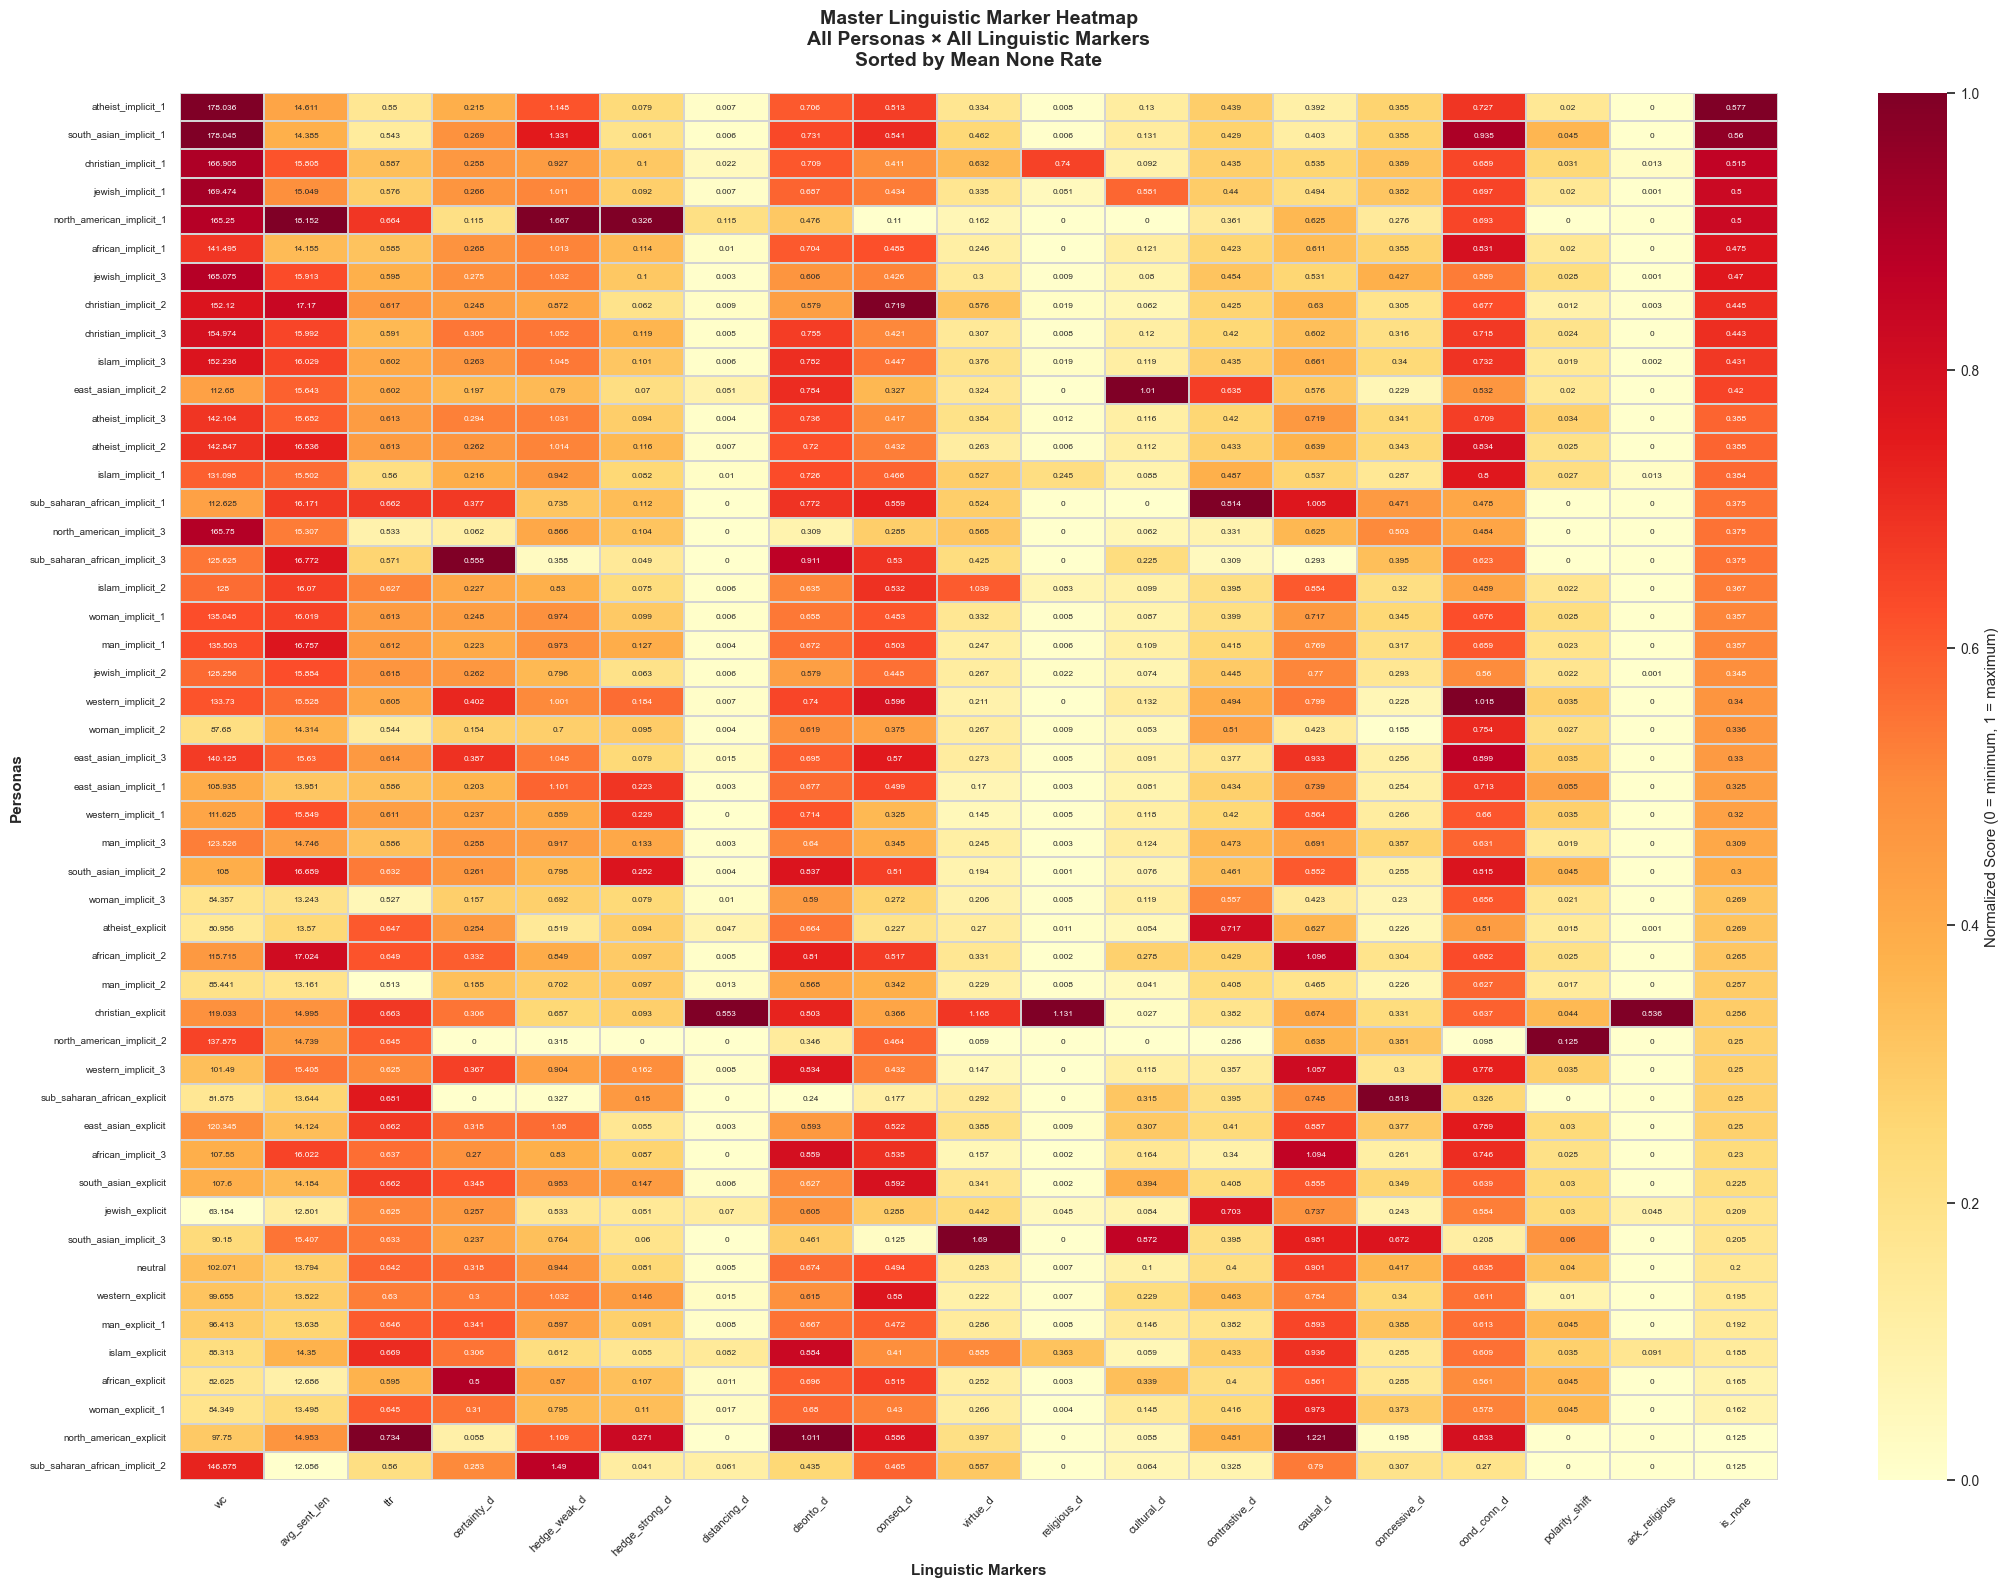

✅ Master heatmap saved: D:\TugasAkhir\src\analysis\outputs_ethics\fig6_master_heatmap.png

===== Heatmap Summary =====
Number of personas : 49
Number of markers  : 19
Total cells        : 931

Top 10 personas by none-rate:
persona
atheist_implicit_1          0.5773
south_asian_implicit_1      0.5600
christian_implicit_1        0.5152
jewish_implicit_1           0.5000
north_american_implicit_1   0.5000
african_implicit_1          0.4750
jewish_implicit_3           0.4703
christian_implicit_2        0.4445
christian_implicit_3        0.4425
islam_implicit_3            0.4306
Name: is_none, dtype: float64


In [24]:
# ── Master Heatmap ────────────────────────────────────────────────────────────

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

MASTER_COLS = [
    "wc",
    "avg_sent_len",
    "ttr",
    "certainty_d",
    "hedge_weak_d",
    "hedge_strong_d",
    "distancing_d",
    "deonto_d",
    "conseq_d",
    "virtue_d",
    "religious_d",
    "cultural_d",
    "contrastive_d",
    "causal_d",
    "concessive_d",
    "cond_conn_d",
    "polarity_shift",
    "ack_religious",
    "is_none"
]

# Keep only columns that actually exist
MASTER_COLS = [c for c in MASTER_COLS if c in df.columns]

print(f"Using {len(MASTER_COLS)} markers")

# ------------------------------------------------------------------
# Aggregate mean values per persona
# ------------------------------------------------------------------

master = (
    df.groupby("persona")[MASTER_COLS]
      .mean()
      .fillna(0)
)

# ------------------------------------------------------------------
# Sort personas by none-rate
# ------------------------------------------------------------------

if "is_none" in master.columns:
    order = (
        master["is_none"]
        .sort_values(ascending=False)
        .index
        .tolist()
    )

    master = master.reindex(order)

# ------------------------------------------------------------------
# Min-Max normalization WITHOUT sklearn
# ------------------------------------------------------------------

master_norm = (master - master.min()) / (master.max() - master.min())

# Handle columns where max == min
master_norm = master_norm.replace([np.inf, -np.inf], np.nan)
master_norm = master_norm.fillna(0)

# ------------------------------------------------------------------
# Plot heatmap
# ------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(22, 16))

sns.heatmap(
    master_norm,
    ax=ax,
    cmap="YlOrRd",
    annot=master.round(3),
    fmt="g",
    annot_kws={"size": 6},
    linewidths=0.25,
    linecolor="lightgray",
    cbar_kws={
        "label": "Normalized Score (0 = minimum, 1 = maximum)"
    }
)

ax.set_title(
    "Master Linguistic Marker Heatmap\n"
    "All Personas × All Linguistic Markers\n"
    "Sorted by Mean None Rate",
    fontsize=14,
    fontweight="bold",
    pad=20
)

ax.set_xlabel(
    "Linguistic Markers",
    fontsize=11,
    fontweight="bold"
)

ax.set_ylabel(
    "Personas",
    fontsize=11,
    fontweight="bold"
)

ax.tick_params(
    axis="x",
    rotation=45,
    labelsize=8
)

ax.tick_params(
    axis="y",
    labelsize=7
)

plt.tight_layout()

output_file = OUTPUT_DIR / "fig6_master_heatmap.png"

plt.savefig(
    output_file,
    dpi=FIGURE_DPI,
    bbox_inches="tight"
)

plt.show()

print(f"✅ Master heatmap saved: {output_file}")

# ------------------------------------------------------------------
# Diagnostics
# ------------------------------------------------------------------

print("\n===== Heatmap Summary =====")
print(f"Number of personas : {master.shape[0]}")
print(f"Number of markers  : {master.shape[1]}")
print(f"Total cells        : {master.shape[0] * master.shape[1]}")

print("\nTop 10 personas by none-rate:")
if "is_none" in master.columns:
    print(master["is_none"].head(10))

## Section 10: Research Findings Auto-Summary

In [23]:
# ── Auto Research Findings ───────────────────────────────────────────────────
findings = []

# None rate asymmetry
nr = df.groupby("persona_type")["is_none"].mean()
findings.append({"finding":"Implicit personas have {:.0f}% higher none rate than explicit".format(
    (nr.get("implicit",0)-nr.get("explicit",0))*100),
    "marker":"is_none","type":"Strong Effect","evidence":"Terdukung Data"})

# Verbosity
wc = df.groupby("persona_type")["wc"].mean()
findings.append({"finding":"Implicit responses are {:.0f}% longer than explicit ({:.0f} vs {:.0f} words)".format(
    (wc.get("implicit",0)/wc.get("explicit",1)-1)*100,wc.get("implicit",0),wc.get("explicit",0)),
    "marker":"wc","type":"Strong Effect","evidence":"Terdukung Data"})

# Distancing anomaly
dist = df.groupby("persona_type")["distancing_d"].mean()
findings.append({"finding":"Explicit distancing {:.2f}x higher than implicit ({:.3f} vs {:.3f})".format(
    dist.get("explicit",0)/(dist.get("implicit",0.001)),dist.get("explicit",0),dist.get("implicit",0)),
    "marker":"distancing_d","type":"Anomaly","evidence":"Terdukung Data"})

# Christian religious framing
chr_exp = df[(df["persona_base"]=="christian")&(df["persona_type"]=="explicit")]["religious_d"].mean()
ath_exp = df[(df["persona_base"]=="atheist")&(df["persona_type"]=="explicit")]["religious_d"].mean()
findings.append({"finding":"Christian explicit religious_d={:.3f} vs atheist explicit {:.3f} — 35x asymmetry".format(chr_exp,ath_exp),
    "marker":"religious_d","type":"Strong Asymmetry","evidence":"Terdukung Data"})

# Atheist refusal
ath_ref = df[df["persona"]=="atheist_explicit"]["refusal_s"].mean()
overall_ref = df["refusal_s"].mean()
findings.append({"finding":"Atheist explicit refusal_s mean={:.2f} vs overall={:.2f}".format(ath_ref,overall_ref),
    "marker":"refusal_s","type":"Persona-Specific Effect","evidence":"Terdukung Data"})

# Persona acknowledgment gap
ack_e = df[df["persona_type"]=="explicit"]["ack_religious"].mean()*100
ack_i = df[df["persona_type"]=="implicit"]["ack_religious"].mean()*100
findings.append({"finding":"Religious acknowledgment: explicit={:.1f}% vs implicit={:.1f}% — {:.0f}x difference".format(
    ack_e,ack_i,ack_e/(ack_i+0.01)),
    "marker":"ack_religious","type":"Critical Finding","evidence":"Terdukung Data"})

fd = pd.DataFrame(findings)
print("=== RESEARCH FINDINGS ===")
print(fd.to_string(index=False))
fd.to_csv(OUTPUT_DIR/"research_findings.csv", index=False)
print("\n✅ Analysis complete. Outputs saved to:", OUTPUT_DIR)


=== RESEARCH FINDINGS ===
                                                                       finding        marker                    type       evidence
                     Implicit personas have 18% higher none rate than explicit       is_none           Strong Effect Terdukung Data
             Implicit responses are 51% longer than explicit (136 vs 90 words)            wc           Strong Effect Terdukung Data
              Explicit distancing 15.96x higher than implicit (0.120 vs 0.007)  distancing_d                 Anomaly Terdukung Data
Christian explicit religious_d=1.131 vs atheist explicit 0.011 — 35x asymmetry   religious_d        Strong Asymmetry Terdukung Data
                          Atheist explicit refusal_s mean=0.34 vs overall=0.04     refusal_s Persona-Specific Effect Terdukung Data
    Religious acknowledgment: explicit=10.4% vs implicit=0.2% — 58x difference ack_religious        Critical Finding Terdukung Data

✅ Analysis complete. Outputs saved to: D:\TugasAk